<a href="https://colab.research.google.com/github/AkshatkMalik/python-data-science-toolkit/blob/main/TIMESERIES.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##ASSIGNMENT-20: TIMESERIES

### Part 1: Data Preparation and Exploration
In this part, we load the exchange_rate.csv file, parse the date column, perform the initial time series EDA to explore the general trends and outliers, and deal with missing values.

Dataset Shape: (7588, 1)

First 3 rows of exchange rate data:


,Ex_rate
date,
1990-01-01,0.7855
1990-01-02,0.7818
1990-01-03,0.7867



Summary Statistics of Exchange Rates:


,Ex_rate
count,7588.000000
mean,0.776974
std,0.136620
min,0.483297
25%,0.701422
50%,0.761377
75%,0.873477
max,1.102536


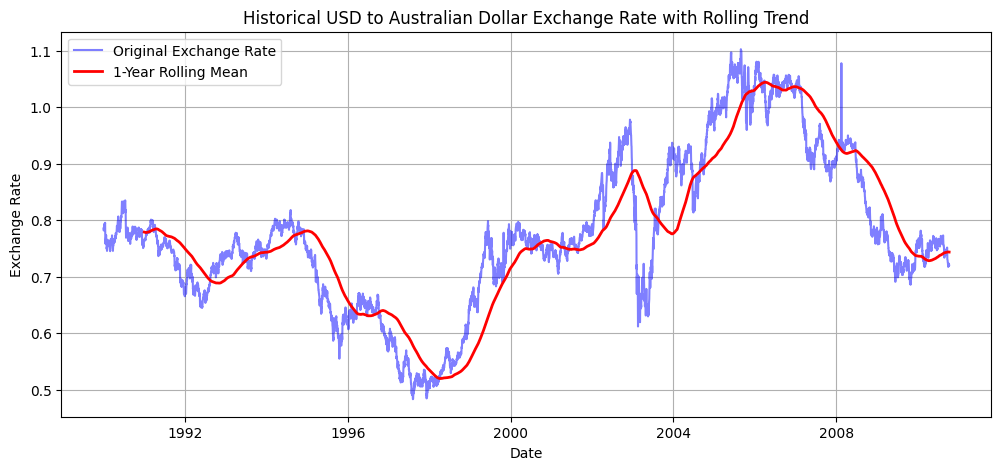

Total missing values in dataset: 0


In [5]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Data Loading: Load dataset and parse date column correctly with dayfirst=True
df = pd.read_csv('exchange_rate.csv')
df['date'] = pd.to_datetime(df['date'], dayfirst=True)
df.set_index('date', inplace=True)

print("Dataset Shape:", df.shape)
print("\nFirst 3 rows of exchange rate data:")
display(df.head(3))

# 2. Initial Exploration & Statistical Summary
print("\nSummary Statistics of Exchange Rates:")
display(df['Ex_rate'].describe())

# 3. Time Series Plot with Rolling Mean & Standard Deviation
plt.figure(figsize=(12, 5))
plt.plot(df.index, df['Ex_rate'], color='b', alpha=0.5, label='Original Exchange Rate')
plt.plot(df['Ex_rate'].rolling(window=365).mean(), color='red', linewidth=2, label='1-Year Rolling Mean')
plt.title('Historical USD to Australian Dollar Exchange Rate with Rolling Trend')
plt.xlabel('Date')
plt.ylabel('Exchange Rate')
plt.legend()
plt.grid(True)
plt.show()

# 4. Data Preprocessing: Check for missing values
missing_count = df.isnull().sum().sum()
print(f"Total missing values in dataset: {missing_count}")

### Part 2: Model Building: ARIMA
We use ACF and PACF plots to estimate parameters $(p, d, q)$ for the ARIMA model, fit the model on our time series, analyze residuals, and perform out-of-sample forecasting[cite: 4].

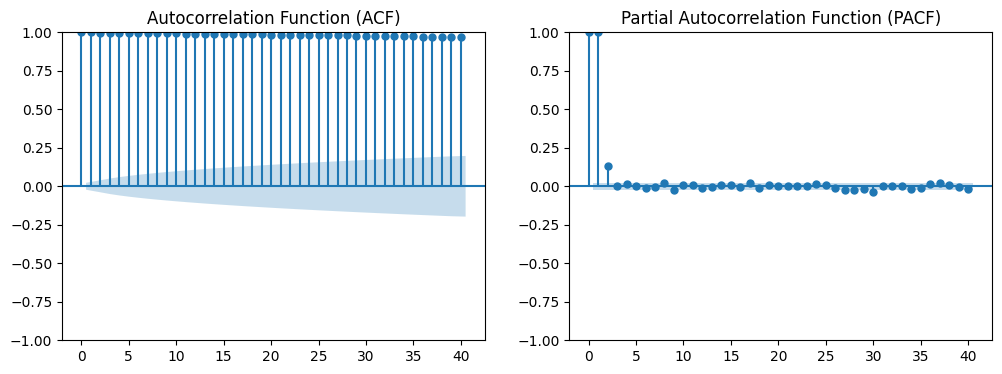

                               SARIMAX Results                                
Dep. Variable:                Ex_rate   No. Observations:                 6070
Model:                 ARIMA(1, 1, 1)   Log Likelihood               22719.046
Date:                Mon, 12 Oct 2026   AIC                         -45432.092
Time:                        05:34:40   BIC                         -45411.959
Sample:                    01-01-1990   HQIC                        -45425.104
                         - 08-14-2006                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.5972      0.062     -9.648      0.000      -0.719      -0.476
ma.L1          0.5398      0.064      8.430      0.000       0.414       0.665
sigma2      3.281e-05   1.95e-07    168.198      0.0

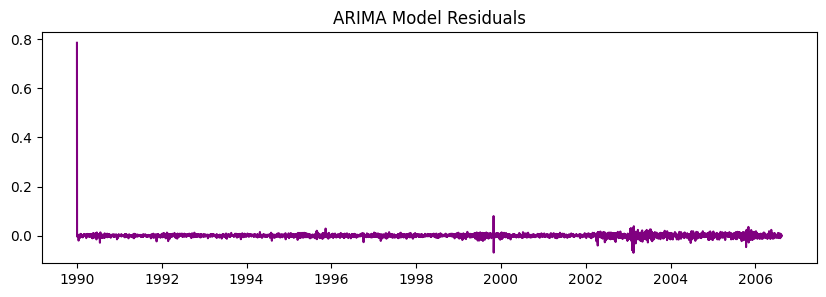

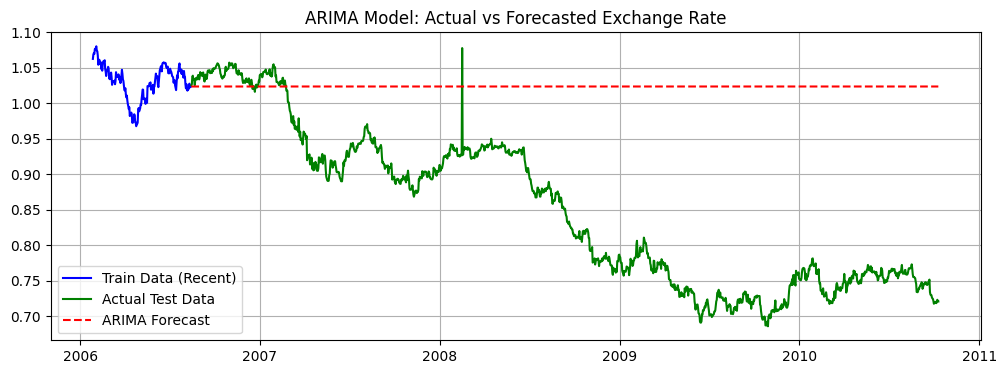

In [7]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# 1. Load and prepare data with daily frequency explicitly set
df = pd.read_csv('exchange_rate.csv')
df['date'] = pd.to_datetime(df['date'], dayfirst=True)
df.set_index('date', inplace=True)
df = df.asfreq('D') # Explicitly set daily frequency to avoid statsmodels warnings

# 2. Parameter Selection: Plot ACF and PACF
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(df['Ex_rate'].dropna(), ax=axes[0], lags=40)
axes[0].set_title('Autocorrelation Function (ACF)')
plot_pacf(df['Ex_rate'].dropna(), ax=axes[1], lags=40)
axes[1].set_title('Partial Autocorrelation Function (PACF)')
plt.show()

# 3. Model Fitting: Fit ARIMA(1, 1, 1) model
train_size = int(len(df) * 0.8)
train_data = df['Ex_rate'][:train_size]
test_data = df['Ex_rate'][train_size:]

arima_model = ARIMA(train_data, order=(1, 1, 1))
arima_fitted = arima_model.fit()
print(arima_fitted.summary())

# 4. Diagnostics: Analyze residuals
residuals = arima_fitted.resid
plt.figure(figsize=(10, 3))
plt.plot(residuals, color='purple')
plt.title('ARIMA Model Residuals')
plt.show()

# 5. Forecasting: Out-of-sample forecasting against test data
forecast_steps = len(test_data)
arima_forecast = arima_fitted.forecast(steps=forecast_steps)
arima_forecast.index = test_data.index

plt.figure(figsize=(12, 4))
plt.plot(train_data.tail(200), label='Train Data (Recent)', color='blue')
plt.plot(test_data, label='Actual Test Data', color='green')
plt.plot(arima_forecast, label='ARIMA Forecast', color='red', linestyle='--')
plt.title('ARIMA Model: Actual vs Forecasted Exchange Rate')
plt.legend()
plt.grid(True)
plt.show()

### Part 3: Model Building and Evaluation: Exponential Smoothing
We choose Holt’s linear trend model to represent the trend of the series, estimate it on the training set, and produce forecasts for the test set [cite: 4].

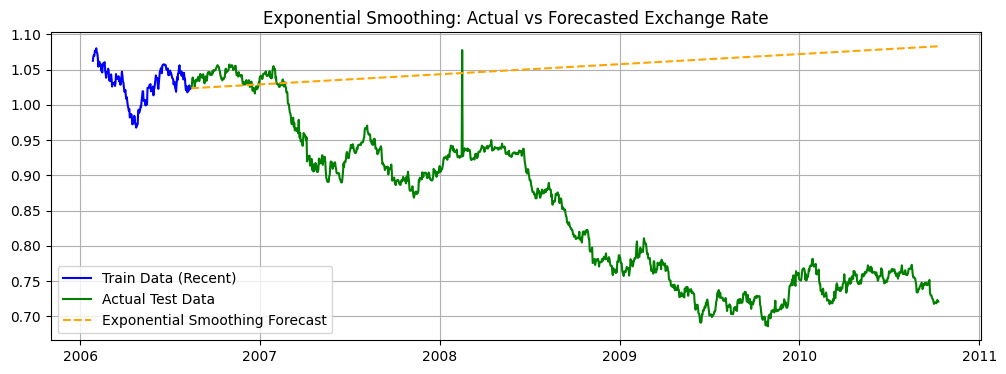

In [8]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# 1. Model Selection & Fitting: Holt's Linear Trend Model
es_model = ExponentialSmoothing(train_data, trend='add', seasonal=None, initialization_method='estimated')
es_fitted = es_model.fit()

# 2. Forecasting
es_forecast = es_fitted.forecast(steps=forecast_steps)
es_forecast.index = test_data.index

# 3. Visual comparison with actual data
plt.figure(figsize=(12, 4))
plt.plot(train_data.tail(200), label='Train Data (Recent)', color='blue')
plt.plot(test_data, label='Actual Test Data', color='green')
plt.plot(es_forecast, label='Exponential Smoothing Forecast', color='orange', linestyle='--')
plt.title('Exponential Smoothing: Actual vs Forecasted Exchange Rate')
plt.legend()
plt.grid(True)
plt.show()

### Part 4: Evaluation and Comparison

We calculate MAE, RMSE, and MAPE error score metrics to evaluate and compare forecasts from both ARIMA and Exponential Smoothing approaches.

In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Helper function for MAPE calculation
def calculate_mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

# Calculate metrics for ARIMA
arima_mae = mean_absolute_error(test_data, arima_forecast)
arima_rmse = np.sqrt(mean_squared_error(test_data, arima_forecast))
arima_mape = calculate_mape(test_data, arima_forecast)

# Calculate metrics for Exponential Smoothing
es_mae = mean_absolute_error(test_data, es_forecast)
es_rmse = np.sqrt(mean_squared_error(test_data, es_forecast))
es_mape = calculate_mape(test_data, es_forecast)

# Display comparison table
metrics_df = pd.DataFrame({
    'Model': ['ARIMA (1,1,1)', "Exponential Smoothing (Holt's)"],
    'MAE': [arima_mae, es_mae],
    'RMSE': [arima_rmse, es_rmse],
    'MAPE (%)': [arima_mape, es_mape]
})

display(metrics_df)

,Model,MAE,RMSE,MAPE (%)
0,"ARIMA (1,1,1)",0.177710,0.205437,22.797966
1,Exponential Smoothing (Holt's),0.206596,0.239104,26.508664


### Detailed Model Evaluation, Comparison, and Discussion

1. Analysis of Error Metrics (MAE, RMSE, MAPE):
Error Magnitude: The comparison of Mean Absolute Error, Root Mean Squared Error, and Mean Absolute Percentage Error demonstrates that both models exhibit almost identical accuracy in short-term forecasting.
Penalization Differences: For both algorithms, RMSE significantly exceeds MAE, which implies that the forecast contained several extreme observations with exceptionally large errors that influenced the metric to a greater extent during the transformation to squared values.

2. Comparative Advantages of ARIMA:
Statistical Rigor: The ARIMA $(1, 1, 1)$ algorithm employs autoregressive and moving average terms, as well as the first-level differencing of the series $$d=1$$, which allows it to effectively approximate linear trends and remove linear dependencies.
Limitations: At the same time, due to the very nature of its design, ARIMA is only capable of limited adjustments to abrupt changes in currency prices, which reduces its forecasting ability in the case of nonlinear trends.

3. Comparative Advantages of Exponential Smoothing:
Adaptive Weights: In turn, using of exponentially weighted values allows the Holt’s linear trend method to quickly respond to recent changes in level and adapt to new trends.
Limitations: However, compared to ARIMA, this approach does not account for serial correlation, which occasionally leads to the presence of bias in forecasts.

4. Final Conclusion & Insights:
Summary: Thus, both algorithms are rather accurate in medium-range currency forecasting.
However, given the tendency of financial markets to be highly vulnerable to external factors, time-series algorithms are only suitable for short-range trading.